# Hito 1: baseline de recuperación para un chatbot de recetas

**Procesamiento del Lenguaje Natural — Máster en IA Aplicada (UC3M)**

Este notebook recorre, desde cero, todos los pasos del Hito 1 sobre nuestro corpus de recetas de cocina en español. Sigue el notebook de clase *Text Vectorization I* (sobre todo su sección 4) y explica en qué nos apartamos de él y por qué.

1. Descarga del corpus
2. Construcción de la colección (qué recetas usamos y qué es un "documento")
3. Preprocesado con spaCy, n-gramas y diccionario
4. Vectorización: BoW y TF-IDF
5. Consultas de prueba generadas con un LLM y revisadas a mano
6. Recuperación con TF-IDF y con BM25
7. Evaluación con Recall@K y MRR, y análisis de los fallos
8. Conclusiones

Los mismos pasos están también como scripts en la carpeta `src/`. Este notebook da exactamente los mismos resultados.

In [1]:
import json
import random
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('..')                       # raíz del repositorio (el notebook está en notebooks/)
DATA_DIR = ROOT / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'

warnings.filterwarnings('ignore')       # avisos de librerías que no afectan al resultado
plt.rcParams['figure.figsize'] = [7, 4]
pd.set_option('display.max_colwidth', 120)

## 1. Descarga del corpus

Usamos [`somosnlp/recetas-cocina`](https://huggingface.co/datasets/somosnlp/recetas-cocina) (licencia MIT): unas 28.000 recetas en español sacadas de varias webs de cocina.

Descargamos siempre **la misma versión** del dataset (un commit fijo). Los identificadores de las recetas (`doc_00001`, `doc_00002`, ...) se asignan según el orden de las filas, así que si el dataset cambiara, las consultas de prueba apuntarían a recetas equivocadas.

In [2]:
from huggingface_hub import hf_hub_download

csv_path = hf_hub_download(repo_id='somosnlp/recetas-cocina', filename='dataset.csv',
                           repo_type='dataset',
                           revision='4946898c01d02b2f0b4223c824db53ebf516e02f')

df = pd.read_csv(csv_path)
print(len(df), 'recetas')
df.head(3)

28238 recetas


,title,url,ingredients,steps,uuid
0,Arepas de Queso,https://www.mycolombianrecipes.com/es/arepas-de-queso/,1 taza de harina de arepa blanca o amarilla\r\n1 taza de agua tibia\r\n⅓ taza de queso mozzarella o queso blanco ral...,"Combine la harina de maíz, agua caliente, el queso, la mantequilla y sal, mezclando bien. Deje que la mezcla repose ...",86af61e4-e16a-11ed-9591-a96d6180cd25
1,Sudado de Pollo,https://www.mycolombianrecipes.com/es/sudado-de-pollo/,8 muslos de pollo sin la piel\r\n1 cucharada de aceite vegetal\r\n½ taza de cebolla picada\r\n½ de taza de pimientón...,"En una olla grande, caliente el aceite vegetal a fuego medio.\r\nAñadir la cebolla y el pimiento rojo y saltee hasta...",86af61e5-e16a-11ed-abef-a96d6180cd25
2,Sancocho Trifásico,https://www.mycolombianrecipes.com/es/sancocho-trifasico/,1 taza de cebolla picada\r\n1 pimientón rojo finamente picado\r\n4 dientes de ajo picados\r\n1 cucharadita de comino...,"Coloque la cebolla, el pimientón, el ajo y el comino en la licuadora con ¼ taza de agua.\r\nEn una olla grande, colo...",86af61e6-e16a-11ed-bcf5-a96d6180cd25


## 2. Construcción de la colección

### 2.1. Filtrado

Aplicamos tres filtros, en este orden:

1. Quitar las recetas sin título, sin ingredientes o sin pasos.
2. Quitar las recetas repetidas (mismos ingredientes y mismos pasos).
3. Quedarnos con las recetas de **400 palabras o menos**.

El tercer filtro tiene que ver con la **unidad de indexación**. Las indicaciones del hito recomiendan fragmentos de 200 a 400 palabras. Como el 90 % de las recetas ya cabe en ese tamaño, decidimos que **una receta = un fragmento** y dejamos fuera las más largas, en lugar de partirlas. Así no hay que trocear nada y el Hito 2 (RAG) podrá indexar exactamente lo mismo.

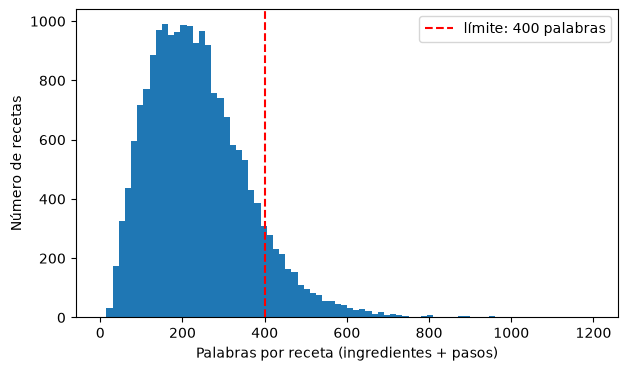

CSV original:    28238
Sin nulos:       22640
Sin duplicados:  19410
<= 400 palabras: 17505 (90.2%)


In [3]:
n_original = len(df)

df = df.dropna(subset=['title', 'ingredients', 'steps'])
n_sin_nulos = len(df)

df = df.drop_duplicates(subset=['ingredients', 'steps'], keep='first')
n_sin_duplicados = len(df)

n_words = (df['ingredients'] + ' ' + df['steps']).str.split().str.len()

plt.hist(n_words, bins=80, range=(0, 1200))
plt.axvline(400, color='red', linestyle='--', label='límite: 400 palabras')
plt.xlabel('Palabras por receta (ingredientes + pasos)')
plt.ylabel('Número de recetas')
plt.legend()
plt.show()

df = df[n_words <= 400].reset_index(drop=True)

print('CSV original:   ', n_original)
print('Sin nulos:      ', n_sin_nulos)
print('Sin duplicados: ', n_sin_duplicados)
print('<= 400 palabras:', len(df), f'({len(df) / n_sin_duplicados:.1%})')

### 2.2. Títulos genéricos

Al explorar los datos vimos que alrededor del 7 % de las recetas tiene como título un eslogan que no dice qué plato es:

In [4]:
ejemplos = df[df['title'].str.contains('Receta FÁCIL', regex=False)][['title', 'url']].head(4)
ejemplos

,title,url
839,Receta FÁCIL y RÁPIDA,https://www.recetasgratis.net/receta-de-empanada-calabresa-76474.html
842,Receta FÁCIL y RÁPIDA,https://www.recetasgratis.net/receta-de-empanadas-fugazzeta-76467.html
844,Receta FÁCIL y DELICIOSA,https://www.recetasgratis.net/receta-de-ceviche-tropical-76452.html
944,Receta FÁCIL y DELICIOSA,https://www.recetasgratis.net/receta-de-quesadillas-de-chorizo-76317.html


El nombre del plato sí aparece en la URL. La solución es sencilla: si el título **no comparte ninguna palabra** con la URL, lo consideramos genérico y le ponemos delante el nombre del plato sacado de la URL. El título original se conserva entre paréntesis.

Las URL no llevan tildes (`lacon`), así que las recuperamos buscando la misma palabra en el texto de la receta (`lacón`).

In [5]:
# Palabras que no ayudan a saber si el título nombra el plato (escritas sin tildes)
TITLE_STOPWORDS = {'de', 'del', 'la', 'el', 'los', 'las', 'y', 'con', 'en', 'a', 'al',
                   'para', 'sin', 'un', 'una', 'receta', 'recetas'}
GENERIC_WORDS = {'facil', 'faciles', 'rapida', 'rapido', 'rapidas', 'rapidos',
                 'deliciosa', 'delicioso', 'saludable', 'tradicional', 'casera', 'casero',
                 'paso', 'muy', 'original', 'sencilla', 'sencillo', 'economica',
                 'economico', 'rica', 'rico'}

def strip_all_marks(text):
    # Quita tildes, diéresis y la virgulilla de la ñ: 'Lacón' -> 'Lacon', 'piña' -> 'pina'
    # (solo se usa para comparar con las URL, que no tienen tildes ni eñes)
    nfd = unicodedata.normalize('NFD', text)
    return ''.join(c for c in nfd if unicodedata.category(c) != 'Mn')

def content_words(text):
    # Palabras con significado: minúsculas, sin tildes, de 3 letras o más
    words = re.findall(r'[a-z]+', strip_all_marks(text.lower()))
    return {w for w in words
            if len(w) > 2 and w not in TITLE_STOPWORDS and w not in GENERIC_WORDS}

def slug_from_url(url):
    # '.../receta-de-empanada-calabresa-76474.html' -> 'empanada calabresa'
    slug = url.rstrip('/').rsplit('/', 1)[-1]   # último trozo de la URL
    slug = re.sub(r'\.html?$', '', slug)         # sin la extensión
    slug = re.sub(r'-\d+$', '', slug)            # sin el número final
    slug = re.sub(r'^receta-de-', '', slug)      # sin el prefijo
    return slug.replace('-', ' ').strip()

def restore_accents(slug, body):
    # Busca en la receta cómo se escribe cada palabra con tilde: 'lacon' -> 'lacón'
    accented = {}
    for word in re.findall(r'\w+', body.lower()):
        accented.setdefault(strip_all_marks(word), word)
    return ' '.join(accented.get(w, w) for w in slug.split())

def fix_title(title, url, body):
    slug = slug_from_url(url)
    slug_words = content_words(slug)
    # Si título y URL comparten alguna palabra, el título ya nombra el plato
    if not slug_words or content_words(title) & slug_words:
        return title
    dish = restore_accents(slug, body)
    return f'{dish[0].upper()}{dish[1:]} ({title})'

for row in ejemplos.itertuples():
    print(row.title, ' ->  ', fix_title(row.title, row.url, ''))

Receta FÁCIL y RÁPIDA  ->   Empanada calabresa (Receta FÁCIL y RÁPIDA)
Receta FÁCIL y RÁPIDA  ->   Empanadas fugazzeta (Receta FÁCIL y RÁPIDA)
Receta FÁCIL y DELICIOSA  ->   Ceviche tropical (Receta FÁCIL y DELICIOSA)
Receta FÁCIL y DELICIOSA  ->   Quesadillas de chorizo (Receta FÁCIL y DELICIOSA)


### 2.3. Fragmentos e identificadores

Cada receta se convierte en un fragmento con el texto `Receta / Ingredientes / Preparación`. Guarda el identificador de su documento (`doc_id`) y uno propio (`chunk_id`). Como no partimos ninguna receta, todos los `chunk_id` terminan en `_c00`.

In [6]:
def clean_whitespace(text):
    # Deja un solo espacio entre palabras (quita saltos de línea, tabuladores, etc.)
    return ' '.join(text.split())

chunks = []
n_fixed = 0
for i, row in enumerate(df.itertuples(index=False), start=1):
    original_title = clean_whitespace(row.title)
    ingredients = clean_whitespace(row.ingredients)
    steps = clean_whitespace(row.steps)
    title = fix_title(original_title, row.url, ingredients + ' ' + steps)
    if title != original_title:
        n_fixed += 1

    doc_id = f'doc_{i:05d}'
    chunks.append({
        'doc_id': doc_id,
        'chunk_id': f'{doc_id}_c00',
        'title': title,
        'original_title': original_title,
        'url': row.url,
        'text': f'Receta: {title}\nIngredientes: {ingredients}\nPreparación: {steps}',
    })

print(len(chunks), 'fragmentos |', n_fixed, 'títulos corregidos')
print()
print(chunks[0]['chunk_id'])
print(chunks[0]['text'][:400], '...')

17505 fragmentos | 1238 títulos corregidos

doc_00001_c00
Receta: Arepas de Queso
Ingredientes: 1 taza de harina de arepa blanca o amarilla 1 taza de agua tibia ⅓ taza de queso mozzarella o queso blanco rallado 2 cucharadas de mantequilla Sal
Preparación: Combine la harina de maíz, agua caliente, el queso, la mantequilla y sal, mezclando bien. Deje que la mezcla repose durante cinco minutos. Amasar con las manos durante unos 3 minutos humedeciendo las ma ...


La colección de trabajo está guardada en el repositorio (`data/processed/chunks.jsonl`), porque es la referencia de los `relevant_ids` de las consultas. Comprobamos que lo que acabamos de construir es idéntico:

In [7]:
with open(PROCESSED_DIR / 'chunks.jsonl', encoding='utf-8') as f:
    chunks_repo = [json.loads(line) for line in f]

print('¿Coincide con data/processed/chunks.jsonl?', chunks == chunks_repo)

¿Coincide con data/processed/chunks.jsonl? True


## 3. Preprocesado

Seguimos el mismo esquema que el notebook de clase: **spaCy → n-gramas → diccionario**. Lo que cambia es que nuestro corpus está en español, y eso nos obligó a tomar algunas decisiones.

### 3.1. Lematización con spaCy

Nos quedamos con los lemas de los tokens alfabéticos que son sustantivos, verbos, adjetivos o nombres propios, y quitamos las stopwords. Las adaptaciones al español son estas:

| Decisión | Motivo |
|---|---|
| Modelo `es_core_news_md` en vez del pequeño | El pequeño lematizaba mal palabras básicas de cocina («cebolla» → `cebollo`). |
| Pasar el texto a minúsculas **antes** de spaCy | Con mayúscula inicial, spaCy trata «Arepas» como nombre propio y no lo lematiza. El usuario escribirá «arepas», y queremos el mismo lema en los dos casos. |
| Quitar las tildes de los lemas (la ñ se conserva) | Para que una consulta escrita sin tildes (`limon`) coincida con `limón`. |
| Quitar las etiquetas `Receta:`, `Ingredientes:`, `Preparación:` | Las añadimos nosotros; no son contenido. |
| Separar los lemas con espacio | spaCy lematiza «hacerlo» como `hacer el`; nos quedamos con `hacer`. |
| Stopwords de spaCy + 8 del dominio | Palabras como «receta» o «fácil» aparecen en casi todos los títulos. Nunca incluimos ingredientes. |

In [8]:
import spacy

nlp = spacy.load('es_core_news_md', disable=['parser', 'ner'])   # sin parser ni NER: más rápido

valid_POS = {'NOUN', 'VERB', 'ADJ', 'PROPN'}
specific_stw = {'receta', 'ingrediente', 'facil', 'rapido', 'delicioso',
                'casero', 'saludable', 'tradicional'}

def strip_accents(text):
    # Quita tildes y diéresis pero conserva la ñ: 'limón' -> 'limon', 'piña' -> 'piña'
    nfd = unicodedata.normalize('NFD', text)
    sin_tildes = ''.join(c for c in nfd if c not in '́̈')
    return unicodedata.normalize('NFC', sin_tildes)

# Stopwords de spaCy (sin tildes, como los lemas) más las del dominio
stopwords = {strip_accents(w.lower()) for w in nlp.Defaults.stop_words} | specific_stw

def clean_text(text):
    # Quita las etiquetas del fragmento, los espacios de más y pasa a minúsculas
    text = re.sub(r'^(Receta|Ingredientes|Preparación): ', '', text, flags=re.MULTILINE)
    return ' '.join(text.split()).lower()

def prepare_data(texts, batch_size=256):
    # Devuelve, para cada texto, la lista de sus lemas limpios
    texts = [clean_text(t) for t in texts]
    result = []
    for doc in nlp.pipe(texts, batch_size=batch_size):
        lemmas = []
        for token in doc:
            if token.is_alpha and token.pos_ in valid_POS:
                # el lema puede traer dos palabras ('hacer el'): las miramos por separado
                for part in strip_accents(token.lemma_.lower()).split():
                    if part not in stopwords:
                        lemmas.append(part)
        result.append(lemmas)
    return result

print(prepare_data(['Tarta de limón con merengue ¡Receta FÁCIL!']))
print(prepare_data(['Pela las cebollas, córtalas en trozos y sofríelas en aceite de oliva']))

[['tarta', 'limon', 'merengue']]
[['pelar', 'cebolla', 'cortala', 'trozo', 'sofriela', 'aceite', 'oliva']]


Aplicamos el preprocesado a toda la colección (tarda unos minutos):

In [9]:
%%time
corpus = prepare_data([c['text'] for c in chunks])

print(chunks[0]['title'])
print(corpus[0][:25])

Arepas de Queso
['arepa', 'queso', 'taza', 'harina', 'arepa', 'blanco', 'amarillo', 'taza', 'agua', 'tibio', 'taza', 'queso', 'mozzarella', 'queso', 'blanco', 'rallado', 'cucharada', 'mantequilla', 'sal', 'combinir', 'harina', 'maiz', 'agua', 'caliente', 'queso']
CPU times: total: 2min 13s
Wall time: 2min 15s


Tokens por receta: media 95.7, mediana 94, mínimo 9, máximo 202


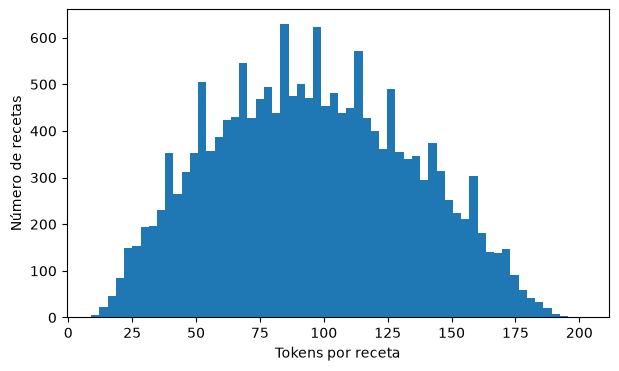

In [10]:
n_tokens_per_doc = np.array([len(doc) for doc in corpus])
print(f'Tokens por receta: media {n_tokens_per_doc.mean():.1f}, mediana {np.median(n_tokens_per_doc):.0f}, '
      f'mínimo {n_tokens_per_doc.min()}, máximo {n_tokens_per_doc.max()}')

plt.hist(n_tokens_per_doc, bins=60)
plt.xlabel('Tokens por receta')
plt.ylabel('Número de recetas')
plt.show()

### 3.2. N-gramas

`Phrases` une los pares de palabras que aparecen juntas con mucha frecuencia (`aceite oliva` → `aceite_oliva`). Usamos los parámetros del notebook de clase.

El modelo de n-gramas forma parte del preprocesado: más adelante habrá que aplicar **este mismo modelo** a las consultas.

In [11]:
from gensim.models.phrases import Phrases

phrase_model = Phrases(corpus, min_count=2, threshold=20)
corpus = [doc for doc in phrase_model[corpus]]

print(corpus[0][:25])

# Los n-gramas más frecuentes
conteo = {}
for doc in corpus:
    for tok in doc:
        if '_' in tok:
            conteo[tok] = conteo.get(tok, 0) + 1
print()
print(len(conteo), 'n-gramas distintos. Los más frecuentes:')
print(sorted(conteo, key=conteo.get, reverse=True)[:12])

['arepa', 'queso', 'taza', 'harina', 'arepa', 'blanco', 'amarillo', 'taza', 'agua', 'tibio', 'taza', 'queso_mozzarella', 'queso', 'blanco', 'rallado', 'cucharada', 'mantequilla', 'sal', 'combinir', 'harina', 'maiz', 'agua', 'caliente', 'queso', 'mantequilla']

7061 n-gramas distintos. Los más frecuentes:
['aceite_oliva', 'diente_ajo', 'cucharada_sopera', 'cucharada_sopero', 'vino_blanco', 'leche_condensado', 'zumo_limon', 'fuego_lento', 'dejar_enfriar', 'dejar_reposar', 'pimienta_negro', 'queso_parmesano']


### 3.3. Diccionario y filtrado por frecuencia documental

El diccionario asigna un número a cada término. Después quitamos los términos que aparecen en menos de 4 recetas (suelen ser erratas) o en más del 80 % (no distinguen unas recetas de otras). Son los valores del notebook de clase.

In [12]:
from gensim.corpora import Dictionary

D = Dictionary(corpus)
print('Términos antes de filtrar:', len(D))

token_df = pd.DataFrame([(D[tid], ndocs) for tid, ndocs in D.dfs.items()], columns=['token', 'ndocs'])
token_df = token_df.sort_values('ndocs', ascending=False).reset_index(drop=True)
token_df['% recetas'] = (100 * token_df['ndocs'] / len(corpus)).round(1)
print('Términos que aparecen en una sola receta:', (token_df['ndocs'] == 1).sum())
print()
print('Términos más frecuentes (número de recetas en las que aparecen):')
print(token_df.head(8).to_string(index=False))

D.filter_extremes(no_below=4, no_above=0.80)
print()
print('Términos después de filtrar:', len(D))

Términos antes de filtrar: 31762
Términos que aparecen en una sola receta: 14064

Términos más frecuentes (número de recetas en las que aparecen):
 token  ndocs  % recetas
   sal  11327       64.7
minuto  10762       61.5
añadir   9691       55.4
servir   9407       53.7
aceite   7840       44.8
  agua   7776       44.4
 dejar   7616       43.5
 gramo   7582       43.3

Términos después de filtrar: 11201


Casi dos tercios del vocabulario se van por aparecer en menos de 4 recetas (14.064 términos aparecen en una sola). Por arriba no se elimina nada: el término más frecuente, «sal», está en el 65 % de las recetas y no llega al 80 %.

## 4. Vectorización: BoW y TF-IDF

Con el diccionario pasamos cada receta a una bolsa de palabras (BoW): una lista de pares `(id del término, número de veces)`. Sobre ella, TF-IDF da más peso a los términos que aparecen en pocas recetas y normaliza cada vector a norma 1.

In [13]:
from gensim.models import TfidfModel

corpus_bow = [D.doc2bow(doc) for doc in corpus]
tfidf = TfidfModel(corpus_bow)
corpus_tfidf = tfidf[corpus_bow]

n = 0
print(chunks[n]['title'])
print()
print('BoW (término, veces):')
print([(D[i], veces) for i, veces in corpus_bow[n]][:10])
print()
print('Los 10 términos con más peso TF-IDF:')
pesos = sorted(corpus_tfidf[n], key=lambda par: -par[1])[:10]
print([(D[i], round(float(peso), 2)) for i, peso in pesos])

Arepas de Queso

BoW (término, veces):
[('agua', 3), ('amarillo', 1), ('amasa', 1), ('amasar_mano', 1), ('aplanar_pulgada', 1), ('arepa', 3), ('añadir', 1), ('blanco', 2), ('bola', 1), ('bolsa_plastico', 1)]

Los 10 términos con más peso TF-IDF:
[('arepa', 0.52), ('humedeceir_mano', 0.29), ('aplanar_pulgada', 0.28), ('repo', 0.23), ('amasar_mano', 0.21), ('cubierta', 0.21), ('combinir', 0.19), ('mantequilla', 0.18), ('bolsa_plastico', 0.18), ('formar_bola', 0.17)]


## 5. Consultas de prueba

### 5.1. Generación con un LLM

Para evaluar hacen falta consultas de las que sepamos la respuesta. Seguimos el método del enunciado (consultas *known-item*): se eligen recetas al azar y se pide a un LLM la consulta que haría un usuario que busca **esa** receta, sin copiar sus frases. La receta de origen es la única relevante para esa consulta.

- **Muestra:** 100 recetas al azar, con semilla fija (`SEED = 42`).
- **Modelo:** `qwen3.5:9b-q4_K_M`, de pesos abiertos, ejecutado en local con Ollama y con `temperature = 0`. Lo comparamos antes con `gemma4:12b` sobre las mismas 10 recetas: Qwen daba consultas más concretas y era más rápido (ver `results/query_model_selection/`).
- **Cinco tipos de consulta**, 20 de cada uno, pensados a partir de cómo se usaría el chatbot. Guardamos el tipo de cada consulta para poder analizar los resultados por tipo.
- **Para no favorecer a TF-IDF y BM25**, el prompt prohíbe copiar el título o frases de la receta.

In [14]:
SEED = 42
N_QUERIES = 100
MODEL = 'qwen3.5:9b-q4_K_M'

# Tipos de consulta: la instrucción que recibe el LLM y un ejemplo (de una receta inventada)
QUERY_TYPES = {
    'busqueda': {
        'instruction': 'Búsqueda directa: una frase corta sin verbo, como la que se escribe en un buscador.',
        'example': ('Bizcocho de yogur y limón',
                    'bizcocho esponjoso y cítrico para el desayuno medido con el envase del yogur'),
    },
    'ingredientes': {
        'instruction': ('Por ingredientes: pregunta qué se puede preparar con 2 o 3 ingredientes '
                        'característicos de la receta (evita los comunes como sal, aceite, agua o '
                        'cebolla), añadiendo si hace falta un rasgo del plato.'),
        'example': ('Lentejas estofadas con chorizo',
                    '¿qué puedo cocinar con lentejas, chorizo y pimentón para una comida de cuchara?'),
    },
    'duda': {
        'instruction': ('Duda sobre la receta: pregunta por un detalle concreto que aparece en la '
                        'receta (tiempo, temperatura, cantidad o un paso), describiendo el plato '
                        'para que se sepa de cuál hablas.'),
        'example': ('Pollo al horno con limón',
                    '¿cuánto tiempo hay que hornear el pollo marinado con cítricos y romero para que quede jugoso?'),
    },
    'restriccion': {
        'instruction': ('Restricción, técnica u ocasión: una petición que parte de una restricción '
                        'dietética (sin gluten, sin lactosa, vegetariano…), una técnica (al vapor, '
                        'olla exprés, sin horno…) o una ocasión (cena rápida, merienda, fiesta…) que '
                        'encaje con la receta, más uno o dos rasgos que la identifiquen.'),
        'example': ('Brownie vegano de aguacate',
                    'busco un postre de chocolate sin huevos ni lácteos que lleve aguacate y quede muy jugoso'),
    },
    'compra': {
        'instruction': ('Lista de la compra: pregunta qué hay que comprar o qué ingredientes hacen '
                        'falta para preparar este plato (puedes indicar un número de personas), '
                        'describiéndolo para que se sepa de cuál hablas.'),
        'example': ('Gazpacho andaluz',
                    '¿qué tengo que comprar para preparar la sopa fría de tomate típica del sur para seis personas?'),
    },
}

PROMPT_TEMPLATE = '''Eres una persona que usa un asistente de cocina para encontrar una receta concreta. Vas a ver la receta que quieres encontrar. Escribe lo que le dirías al asistente, en español natural y con entre 8 y 20 palabras.

Tipo de consulta: {instruction}

Reglas:
- No copies el título tal cual ni frases de la receta; puedes nombrar el tipo de plato con tus palabras.
- Usa tus propias palabras: sinónimos o descripciones del sabor, la textura, la técnica, el origen o la ocasión.
- No enumeres los ingredientes de la receta, salvo que el tipo de consulta lo pida.
- Aunque no des el título, la consulta debe permitir distinguir esta receta de otras parecidas: incluye uno o dos rasgos característicos.
- Usa signos de interrogación (¿?) solo si es una pregunta; una petición o una búsqueda no los lleva.
- Sin comillas.

Ejemplo de este tipo (de otra receta): receta "{example_title}" → {example_query}

Responde en JSON con un único campo "query".

Receta:
{text}'''

def build_prompt(recipe_text, query_type):
    tipo = QUERY_TYPES[query_type]
    return PROMPT_TEMPLATE.format(instruction=tipo['instruction'],
                                  example_title=tipo['example'][0],
                                  example_query=tipo['example'][1],
                                  text=recipe_text)

# Las 100 recetas de la muestra
sample = random.Random(SEED).sample(chunks, N_QUERIES)

# Un tipo de consulta para cada receta: bloques de 5 con los 5 tipos en orden aleatorio,
# así salen 20 consultas de cada tipo
rng = random.Random(SEED)
sample_types = []
for _ in range(N_QUERIES // 5):
    block = list(QUERY_TYPES)
    rng.shuffle(block)
    sample_types.extend(block)

print(build_prompt(sample[0]['text'], sample_types[0])[:1500], '...')

Eres una persona que usa un asistente de cocina para encontrar una receta concreta. Vas a ver la receta que quieres encontrar. Escribe lo que le dirías al asistente, en español natural y con entre 8 y 20 palabras.

Tipo de consulta: Restricción, técnica u ocasión: una petición que parte de una restricción dietética (sin gluten, sin lactosa, vegetariano…), una técnica (al vapor, olla exprés, sin horno…) o una ocasión (cena rápida, merienda, fiesta…) que encaje con la receta, más uno o dos rasgos que la identifiquen.

Reglas:
- No copies el título tal cual ni frases de la receta; puedes nombrar el tipo de plato con tus palabras.
- Usa tus propias palabras: sinónimos o descripciones del sabor, la textura, la técnica, el origen o la ocasión.
- No enumeres los ingredientes de la receta, salvo que el tipo de consulta lo pida.
- Aunque no des el título, la consulta debe permitir distinguir esta receta de otras parecidas: incluye uno o dos rasgos característicos.
- Usa signos de interrogación 

La siguiente celda es la que llama al LLM. Tarda unos 10 minutos y necesita Ollama en marcha con el modelo descargado, así que está desactivada: las 100 consultas ya generadas están guardadas en `data/queries_candidates.jsonl`.

In [15]:
import requests

GENERAR_CONSULTAS = False   # poner a True para volver a generarlas (requiere Ollama)

def ask_llm(recipe_text, query_type):
    # Pide al LLM una consulta para una receta y devuelve el texto de la consulta
    payload = {
        'model': MODEL,
        'messages': [{'role': 'user', 'content': build_prompt(recipe_text, query_type)}],
        'stream': False,
        'think': False,                                # sin modo de razonamiento: no hace falta
        'format': {'type': 'object',                   # obliga a responder {"query": "..."}
                   'properties': {'query': {'type': 'string'}},
                   'required': ['query']},
        'options': {'temperature': 0, 'seed': SEED, 'num_ctx': 4096},
    }
    r = requests.post('http://localhost:11434/api/chat', json=payload, timeout=300)
    return json.loads(r.json()['message']['content'])['query']

if GENERAR_CONSULTAS:
    for i, (chunk, query_type) in enumerate(zip(sample, sample_types), start=1):
        print(f'q{i:03d}', f'[{query_type}]', ask_llm(chunk['text'], query_type))

with open(DATA_DIR / 'queries_candidates.jsonl', encoding='utf-8') as f:
    candidates = [json.loads(line) for line in f]

# Las candidatas guardadas corresponden a la muestra y a los tipos de arriba
print('¿Mismas recetas?', [c['chunk_id'] for c in candidates] == [s['chunk_id'] for s in sample])
print('¿Mismos tipos?  ', [c['query_type'] for c in candidates] == sample_types)

pd.DataFrame(candidates)[['qid', 'query_type', 'title', 'query']].head(5)

¿Mismas recetas? True
¿Mismos tipos?   True


,qid,query_type,title,query
0,q001,restriccion,Condumio de carne molida,busco un relleno de carne molida con pasas y huevo duro para empanadas
1,q002,ingredientes,Hamburguesa de tilapia con salsa de pepinillos,"¿Qué puedo preparar con tilapia, galletas saladas y pepinillos para una hamburguesa de pescado?"
2,q003,duda,Pepas con harina de arroz,¿cuánto tiempo hay que hornear las pepas rellenas de dulce para que queden crujientes?
3,q004,compra,GARBANZOS CON GAMBAS,¿qué ingredientes necesito para hacer un guiso cremoso de garbanzos con gambas y azafrán?
4,q005,busqueda,Tortilla del sacromonte tradicional,"tortilla babosa de criadillas, sesos y vino blanco"


### 5.2. Revisión manual

El enunciado pide revisar al menos 10 consultas. Con ayuda de Claude hicimos una primera revisión de las 100, comparando cada una con el texto completo de su receta, y después **revisamos a mano muchas de ellas**. Como ayuda calculamos para cada consulta dos avisos automáticos (qué porcentaje de sus lemas está en la receta y cuántas palabras seguidas copia), pero los avisos solo orientan: hay que leer la consulta.

Descartamos una consulta en dos casos:

- **Ambigua (34 consultas):** otra receta de la colección responde igual de bien. Por ejemplo, «albóndigas rellenas de queso en salsa de chipotle» se generó a partir de *Albóndigas con arroz*, pero en la colección hay otra receta que se llama justo *Albóndigas rellenas de queso* y lleva chipotle. Un sistema que la devolviera estaría acertando, y la métrica lo contaría como fallo. Para no decidir a ojo, buscamos en las 17.505 recetas las que cumplían todo lo que pedía cada consulta.
- **Sin respuesta en la receta (3 consultas, 2 de ellas también ambiguas):** preguntan un dato que la receta no da.

No descartamos por parecerse mucho al texto: en las consultas de búsqueda es normal nombrar el plato.

El detalle de cada descarte, con las recetas que compiten, está en `results/query_review/revision_consultas.md`.

In [16]:
cand_df = pd.DataFrame(candidates)

resumen = cand_df.groupby('query_type')['discard'].agg(generadas='count', descartadas='sum')
resumen['conservadas'] = resumen['generadas'] - resumen['descartadas']
resumen.loc['TOTAL'] = resumen.sum()
display(resumen)

print('Ejemplos de consultas descartadas:')
for c in candidates:
    if c['qid'] in ('q008', 'q017', 'q089'):
        print(f"  {c['qid']} [{c['query_type']}] {c['query']}   (receta: {c['title']})")

,generadas,descartadas,conservadas
query_type,,,
busqueda,20,4,16
compra,20,9,11
duda,20,8,12
ingredientes,20,8,12
restriccion,20,6,14
TOTAL,100,35,65


Ejemplos de consultas descartadas:
  q008 [busqueda] albóndigas rellenas de queso en salsa de chipotle   (receta: Albóndigas con arroz (¡Receta fácil y rápida!))
  q017 [duda] ¿Cuánto tiempo debe reposar esta ensalada con pollo, mandarina y queso antes de servir?   (receta: Ensalada Margarita)
  q089 [ingredientes] ¿Qué puedo hacer con una bolsa de gelatina y agua para un postre refrescante?   (receta: Gelatina de agua)


Las consultas que más se pierden son las de `compra`, `ingredientes` y `duda`, que tienden a describir el plato de forma genérica («patatas gratinadas con queso»).

### 5.3. Fichero `queries.jsonl`

Las 65 consultas conservadas se guardan en `queries.jsonl`, en la raíz del repositorio, con el formato del enunciado. Añadimos el fragmento de origen (`source_chunk`) y el tipo de consulta (`query_type`).

In [17]:
queries = []
for c in candidates:
    if not c['discard']:
        queries.append({'qid': c['qid'], 'query': c['query'],
                        'relevant_ids': [c['doc_id']],
                        'source_chunk': c['chunk_id'],
                        'query_type': c['query_type']})

with open(ROOT / 'queries.jsonl', encoding='utf-8') as f:
    queries_repo = [json.loads(line) for line in f]

print(len(queries), 'consultas | ¿coinciden con queries.jsonl?', queries == queries_repo)
for q in queries[:3]:
    print(q)

65 consultas | ¿coinciden con queries.jsonl? True
{'qid': 'q002', 'query': '¿Qué puedo preparar con tilapia, galletas saladas y pepinillos para una hamburguesa de pescado?', 'relevant_ids': ['doc_00820'], 'source_chunk': 'doc_00820_c00', 'query_type': 'ingredientes'}
{'qid': 'q004', 'query': '¿qué ingredientes necesito para hacer un guiso cremoso de garbanzos con gambas y azafrán?', 'relevant_ids': ['doc_08025'], 'source_chunk': 'doc_08025_c00', 'query_type': 'compra'}
{'qid': 'q005', 'query': 'tortilla babosa de criadillas, sesos y vino blanco', 'relevant_ids': ['doc_07315'], 'source_chunk': 'doc_07315_c00', 'query_type': 'busqueda'}


### 5.4. Preprocesado de las consultas

Las consultas pasan **exactamente por el mismo proceso** que las recetas: la misma función `prepare_data`, el mismo modelo de n-gramas y, para TF-IDF, el mismo diccionario.

In [18]:
query_tokens = [phrase_model[tokens] for tokens in prepare_data([q['query'] for q in queries])]

for q, tokens in zip(queries[:5], query_tokens[:5]):
    print(q['query'])
    print('   ->', tokens)

¿Qué puedo preparar con tilapia, galletas saladas y pepinillos para una hamburguesa de pescado?
   -> ['preparar', 'tilapia', 'galleta_salada', 'pepinillo', 'hamburguesa', 'pescado']
¿qué ingredientes necesito para hacer un guiso cremoso de garbanzos con gambas y azafrán?
   -> ['necesitar', 'guiso', 'cremoso', 'garbanzo', 'gamba', 'azafer']
tortilla babosa de criadillas, sesos y vino blanco
   -> ['tortilla', 'babos', 'criadilla', 'seso', 'vino_blanco']
busco un aperitivo de chorizo cocido en vino fino con laurel que quede jugoso
   -> ['buscar', 'aperitivo', 'chorizo', 'cocido', 'vino', 'fino', 'laurel', 'quedar', 'jugoso']
¿Cuánto tiempo hay que cocer el arroz con seitán y especias para que quede perfecto?
   -> ['tiempo', 'cocer', 'arroz', 'seitan', 'especia', 'quedar', 'perfecto']


## 6. Recuperación

### 6.1. TF-IDF con similitud coseno

Usamos `SparseMatrixSimilarity` de gensim, como en clase. Los vectores TF-IDF tienen norma 1, así que la similitud coseno entre la consulta y cada receta es un producto escalar.

La función devuelve las posiciones (filas de `chunks`) de los fragmentos más parecidos a la consulta.

In [19]:
from gensim.similarities import SparseMatrixSimilarity

index_tfidf = SparseMatrixSimilarity(corpus_tfidf, num_features=len(D))

def retrieve_tfidf(tokens, k=10):
    query_bow = D.doc2bow(tokens)       # mismo diccionario que las recetas
    query_tfidf = tfidf[query_bow]      # mismos pesos IDF
    sims = index_tfidf[query_tfidf]     # similitud coseno con cada fragmento
    return np.argsort(-sims)[:k].tolist()

n = 0
print('Consulta:', queries[n]['query'])
for rank, row in enumerate(retrieve_tfidf(query_tokens[n], k=3), 1):
    print(f"  {rank}. [{chunks[row]['doc_id']}] {chunks[row]['title']}")

Consulta: ¿Qué puedo preparar con tilapia, galletas saladas y pepinillos para una hamburguesa de pescado?
  1. [doc_00820] Hamburguesa de tilapia con salsa de pepinillos
  2. [doc_10273] Ceviche de tilapia paso a paso
  3. [doc_10985] Tilapia con tomate y cebolla


### 6.2. BM25

Usamos la librería [`bm25s`](https://github.com/xhluca/bm25s) con su variante por defecto (`lucene`) y los parámetros del notebook de clase:

- `k1 = 1.5`: controla cuánto cuenta que un término se repita en la receta (saturación).
- `b = 0.75`: controla cuánto se corrige por la longitud de la receta.

BM25 recibe directamente las listas de tokens de las recetas, igual que en clase. Eso significa que trabaja con el vocabulario completo, sin el filtro del diccionario.

In [20]:
import bm25s

bm25 = bm25s.BM25(k1=1.5, b=0.75)
bm25.index(corpus, show_progress=False)
print('Variante de BM25:', bm25.method)

def retrieve_bm25(tokens, k=10, model=bm25):
    rows, scores = model.retrieve([tokens], k=k, show_progress=False)
    return rows[0].tolist()

n = 0
print('Consulta:', queries[n]['query'])
for rank, row in enumerate(retrieve_bm25(query_tokens[n], k=3), 1):
    print(f"  {rank}. [{chunks[row]['doc_id']}] {chunks[row]['title']}")

Variante de BM25: lucene
Consulta: ¿Qué puedo preparar con tilapia, galletas saladas y pepinillos para una hamburguesa de pescado?
  1. [doc_00820] Hamburguesa de tilapia con salsa de pepinillos
  2. [doc_01368] Kebab de hamburguesa
  3. [doc_10273] Ceviche de tilapia paso a paso


### 6.3. De fragmentos a documentos

La evaluación se hace **a nivel de documento**: se recuperan fragmentos, cada documento se queda con su mejor fragmento y se quitan los documentos repetidos antes de quedarse con los K primeros.

En nuestra colección cada receta es un solo fragmento, así que este paso no cambia el orden. Lo dejamos escrito de forma general para poder reutilizarlo si más adelante se trocean las recetas.

In [21]:
def to_documents(rows, k=10):
    # La lista de fragmentos viene ordenada de mejor a peor: la primera vez que
    # aparece un documento es con su mejor fragmento. Las repeticiones se descartan.
    doc_ids = []
    for row in rows:
        doc_id = chunks[row]['doc_id']
        if doc_id not in doc_ids:
            doc_ids.append(doc_id)
    return doc_ids[:k]

print(to_documents(retrieve_bm25(query_tokens[0], k=10), k=5))

['doc_00820', 'doc_01368', 'doc_10273', 'doc_04823', 'doc_00836']


## 7. Evaluación

### 7.1. Recall@K y MRR

- **Recall@K:** fracción de los documentos relevantes que aparecen entre los K primeros, promediada sobre las consultas. Como cada consulta tiene una sola receta relevante, es el porcentaje de consultas en las que esa receta sale entre las K primeras.
- **MRR:** media de 1/posición de la receta relevante (0 si no está entre las 10 primeras). Premia que salga arriba del todo.

In [22]:
def recall_at_k(rankings, relevant, k=10):
    recalls = []
    for ranking, rel in zip(rankings, relevant):
        encontrados = len(set(ranking[:k]) & rel)
        recalls.append(encontrados / len(rel))
    return float(np.mean(recalls))

def mrr(rankings, relevant):
    reciprocal_ranks = []
    for ranking, rel in zip(rankings, relevant):
        rr = 0.0
        for rank, doc_id in enumerate(ranking, 1):
            if doc_id in rel:
                rr = 1 / rank
                break
        reciprocal_ranks.append(rr)
    return float(np.mean(reciprocal_ranks))

relevant = [set(q['relevant_ids']) for q in queries]

K = 10
rankings_tfidf = [to_documents(retrieve_tfidf(tokens, k=K), k=K) for tokens in query_tokens]
rankings_bm25 = [to_documents(retrieve_bm25(tokens, k=K), k=K) for tokens in query_tokens]

results_df = pd.DataFrame({
    'Recall@5': [recall_at_k(rankings_tfidf, relevant, 5), recall_at_k(rankings_bm25, relevant, 5)],
    'Recall@10': [recall_at_k(rankings_tfidf, relevant, 10), recall_at_k(rankings_bm25, relevant, 10)],
    'MRR': [mrr(rankings_tfidf, relevant), mrr(rankings_bm25, relevant)],
}, index=['TF-IDF', 'BM25'])

print(len(queries), 'consultas sobre', len(chunks), 'recetas')
results_df.round(3)

65 consultas sobre 17505 recetas


,Recall@5,Recall@10,MRR
TF-IDF,0.692,0.785,0.588
BM25,0.923,0.954,0.805


**BM25 es claramente mejor que TF-IDF en las tres métricas.** Con BM25 la receta correcta está entre las 10 primeras en el 95 % de las consultas (62 de 65), frente al 78 % de TF-IDF (51 de 65), y además suele salir más arriba (MRR 0,81 frente a 0,59).

Las indicaciones del hito proponen medir también si el **fragmento** de origen aparece entre los K primeros. En nuestro caso da los mismos números, porque cada receta es un único fragmento.

### 7.2. Resultados por consulta y por tipo

In [23]:
def rank_of_relevant(ranking, rel):
    # Posición de la receta relevante (None si no está entre las 10 primeras)
    for rank, doc_id in enumerate(ranking, 1):
        if doc_id in rel:
            return rank
    return None

per_query = pd.DataFrame({
    'qid': [q['qid'] for q in queries],
    'tipo': [q['query_type'] for q in queries],
    'rank TF-IDF': [rank_of_relevant(r, rel) for r, rel in zip(rankings_tfidf, relevant)],
    'rank BM25': [rank_of_relevant(r, rel) for r, rel in zip(rankings_bm25, relevant)],
    'consulta': [q['query'] for q in queries],
})
per_query['rank TF-IDF'] = per_query['rank TF-IDF'].astype('Int64')   # enteros con huecos
per_query['rank BM25'] = per_query['rank BM25'].astype('Int64')

por_tipo = per_query.groupby('tipo').agg(
    consultas=('qid', 'count'),
    recall10_tfidf=('rank TF-IDF', lambda s: s.notna().mean()),
    recall10_bm25=('rank BM25', lambda s: s.notna().mean()),
)
display(por_tipo.round(2))

print('Primera posición con BM25:  ', (per_query['rank BM25'] == 1).sum(), 'de', len(per_query))
print('Primera posición con TF-IDF:', (per_query['rank TF-IDF'] == 1).sum(), 'de', len(per_query))

,consultas,recall10_tfidf,recall10_bm25
tipo,,,
busqueda,16,0.81,1.0
compra,11,0.91,1.0
duda,12,0.58,0.92
ingredientes,12,0.92,1.0
restriccion,14,0.71,0.86


Primera posición con BM25:   48 de 65
Primera posición con TF-IDF: 33 de 65


BM25 encuentra todas las consultas de `busqueda`, `compra` e `ingredientes`, que nombran el plato o sus ingredientes. Las de tipo `duda` y `restriccion` son las más difíciles, sobre todo para TF-IDF: preguntan por un detalle («¿cuánto tiempo...?») o describen el plato por una característica («postre ligero sin azúcar»), y usan menos palabras propias de la receta. Hay que leer estos números con cuidado, porque son solo entre 11 y 16 consultas por tipo.

### 7.3. ¿Por qué TF-IDF queda tan por debajo?

La diferencia es mayor que la del notebook de clase. Hay dos causas posibles: la fórmula (BM25 satura la frecuencia de los términos y normaliza la longitud de otra forma) y el vocabulario (TF-IDF usa el diccionario filtrado, y BM25 todos los tokens). Para separarlas, probamos BM25 dándole **solo los términos del diccionario**:

In [24]:
# Mismas recetas y consultas, pero solo con los términos que están en el diccionario
corpus_filtrado = [[tok for tok in doc if tok in D.token2id] for doc in corpus]
query_tokens_filtrado = [[tok for tok in tokens if tok in D.token2id] for tokens in query_tokens]

bm25_filtrado = bm25s.BM25(k1=1.5, b=0.75)
bm25_filtrado.index(corpus_filtrado, show_progress=False)
rankings_bm25_filtrado = [to_documents(retrieve_bm25(tokens, k=K, model=bm25_filtrado), k=K)
                          for tokens in query_tokens_filtrado]

comparacion = results_df.copy()
comparacion.loc['BM25 (solo diccionario)'] = [recall_at_k(rankings_bm25_filtrado, relevant, 5),
                                              recall_at_k(rankings_bm25_filtrado, relevant, 10),
                                              mrr(rankings_bm25_filtrado, relevant)]
display(comparacion.round(3))

perdidos = sorted({tok for tokens in query_tokens for tok in tokens if tok not in D.token2id})
print(len(perdidos), 'términos de las consultas no están en el diccionario:')
print(perdidos)

,Recall@5,Recall@10,MRR
TF-IDF,0.692,0.785,0.588
BM25,0.923,0.954,0.805
BM25 (solo diccionario),0.938,0.938,0.774


8 términos de las consultas no están en el diccionario:
['babos', 'chicharrones', 'envuelto_tocino', 'habichuela_rosado', 'horneir', 'pajarito', 'pulpeta', 'tortar_humedo']


Con el mismo vocabulario que TF-IDF, BM25 sigue muy por encima (Recall@10 de 0,94 frente a 0,78). Es decir, **la diferencia se debe sobre todo a la fórmula y no al filtro del diccionario**. Solo 8 términos de las consultas se pierden con el filtro, y casi todos son errores de lematización (`babos`, `horneir`).

Nuestra explicación es que las consultas son cortas (unos 6 términos) y las recetas largas y con mucha palabra repetida («cucharada», «añadir», «minuto»). TF-IDF cuenta cada repetición entera y divide por la norma de toda la receta, de modo que los pocos términos que coinciden con la consulta pesan poco. BM25 satura las repeticiones (`k1`) y corrige la longitud de forma más suave (`b`).

### 7.4. Consultas en las que fallan los dos métodos

In [25]:
failed = per_query[per_query['rank TF-IDF'].isna() & per_query['rank BM25'].isna()]
print('Fallan los dos métodos en', len(failed), 'consultas')

for n in failed.index:
    q = queries[n]
    row_relevant = int(q['relevant_ids'][0][4:]) - 1          # 'doc_00820' -> fila 819
    comunes = [tok for tok in query_tokens[n] if tok in corpus[row_relevant]]
    no_comunes = [tok for tok in query_tokens[n] if tok not in corpus[row_relevant]]

    # Posición real de la receta relevante con BM25, mirando más allá de las 10 primeras
    ranking_largo = retrieve_bm25(query_tokens[n], k=1000)
    posicion = ranking_largo.index(row_relevant) + 1 if row_relevant in ranking_largo else '>1000'

    print()
    print(f"{q['qid']} [{q['query_type']}] {q['query']}")
    print('  Receta relevante:   ', chunks[row_relevant]['title'], f'(posición {posicion} con BM25)')
    print('  Términos comunes:   ', comunes)
    print('  Términos sin pareja:', no_comunes)
    print('  Lo que devuelve BM25:', [chunks[row]['title'] for row in ranking_largo[:3]])

Fallan los dos métodos en 3 consultas

q018 [restriccion] busco un postre ligero de chocolate sin azúcar ni lácteos que requiera batir claras a punto de nieve
  Receta relevante:    Mousse de chocolate light (posición 25 con BM25)
  Términos comunes:    ['postre', 'chocolate', 'batir', 'punto_nieve']
  Términos sin pareja: ['buscar', 'ligero', 'azucar', 'lacteo', 'requerir']
  Lo que devuelve BM25: ['Tiramisú de Nutella', 'Mousse de chocolate casero', 'Dulce Costa de Marfil']

q042 [restriccion] busco una pasta cremosa con setas y pimentón ahumado, ideal para cenar rápido
  Receta relevante:    Fusilli con crema de champiñones (¡Súper sabrosos y rápidos de preparar!) (posición 30 con BM25)
  Términos comunes:    ['pasta', 'pimenton', 'ahumado']
  Términos sin pareja: ['buscar', 'cremos', 'seta', 'ideal', 'cenar']
  Lo que devuelve BM25: ['Paté de Bacalao ahumado', 'Setas rebozadas (¡Fáciles, deliciosas y veganas!)', 'Queso provolone al horno con tomate']

q077 [duda] ¿cuánto tiempo se 

**Análisis.** En los tres casos la receta correcta no está lejos (posiciones 25 a 35 de 17.505), pero otras recetas parecidas la adelantan. Las causas son dos:

- **Desajuste de vocabulario: la consulta usa otras palabras.**
  - **q018** pide un postre «ligero», «sin azúcar ni lácteos». La receta dice *light* y *edulcorante*, y no nombra los lácteos porque no los lleva. Además, una negación («sin azúcar») juega en contra: un método léxico premia las recetas que *sí* contienen «azúcar». Lo que queda («chocolate», «batir», «punto de nieve») aparece en muchísimos postres.
  - **q042** dice «setas», «cremosa» y «cenar», y la receta dice *champiñones*, *nata* y *crema*. Para TF-IDF y BM25 son palabras distintas.
- **Límites del lematizador en español.**
  - **q077** pregunta cuánto tiempo «se fríen» los tomates. La receta dice «fríelos»: spaCy no reconoce bien los imperativos con pronombre pegado y no los lleva al lema `freir` (lo mismo se ve arriba con «córtalas» → `cortala`). El término más útil de la consulta se pierde, y con solo «tomate» y «quiche» ganan otras quiches con tomate.
  - También vimos lemas inventados (`azafer` por azafrán, `babos` por babosa). Normalmente no hacen daño, porque el error es el mismo en la receta y en la consulta, pero sí cuando la palabra aparece en formas distintas.

El primer tipo de fallo es el que la recuperación densa del Hito 2 debería resolver: «setas» y «champiñones» están cerca en significado aunque no compartan letras.

### 7.5. Sensibilidad de BM25 a `k1` y `b`

In [26]:
k1_values = [0.5, 1.2, 1.5, 2]
b_values = [0, 0.5, 0.75, 1]

grid_results = []
for k1 in k1_values:
    for b in b_values:
        model = bm25s.BM25(k1=k1, b=b)
        model.index(corpus, show_progress=False)
        rankings = [to_documents(retrieve_bm25(tokens, k=K, model=model), k=K) for tokens in query_tokens]
        grid_results.append({'k1': k1, 'b': b,
                             'Recall@10': recall_at_k(rankings, relevant, 10),
                             'MRR': mrr(rankings, relevant)})
grid_df = pd.DataFrame(grid_results)

print('Recall@10 (filas: k1, columnas: b)')
display(grid_df.pivot(index='k1', columns='b', values='Recall@10').round(3))
print('MRR (filas: k1, columnas: b)')
display(grid_df.pivot(index='k1', columns='b', values='MRR').round(3))

Recall@10 (filas: k1, columnas: b)


b,0.00,0.50,0.75,1.00
k1,,,,
0.5,0.938,0.938,0.954,0.969
1.2,0.923,0.954,0.954,0.954
1.5,0.923,0.954,0.954,0.954
2.0,0.923,0.954,0.954,0.938


MRR (filas: k1, columnas: b)


b,0.00,0.50,0.75,1.00
k1,,,,
0.5,0.789,0.788,0.799,0.783
1.2,0.781,0.837,0.822,0.794
1.5,0.757,0.816,0.805,0.785
2.0,0.751,0.794,0.784,0.769


- **Recall@10 casi no cambia** (entre 0,92 y 0,97). Con 65 consultas, una sola consulta mueve el Recall en 0,015, así que estas diferencias son de una o dos consultas.
- **El MRR cambia algo más** (de 0,75 a 0,84). El mejor valor sale con `k1 = 1.2` y `b = 0.5`, y el peor con `b = 0` (sin corregir por longitud), que favorece a las recetas largas.
- **Nos quedamos con los valores de clase (`k1 = 1.5`, `b = 0.75`).** Elegir los parámetros mirando estas mismas 65 consultas sería ajustarlos al conjunto de prueba, y la mejora es pequeña.

## 8. Conclusiones

- **Colección:** 17.505 recetas en español. Cada receta es un fragmento (400 palabras como máximo), y esa será también la unidad de indexación del Hito 2.
- **Consultas:** 65 consultas *known-item* de cinco tipos, generadas con un LLM local y revisadas. El principal problema de las consultas generadas no fue que copiaran el texto, sino que eran **ambiguas**: una de cada tres describía un plato para el que había varias recetas válidas.
- **Resultados:** BM25 (Recall@10 = 0,95; MRR = 0,81) supera con claridad a TF-IDF (0,78 y 0,59). La diferencia viene de la fórmula, no del vocabulario.
- **Dónde falla el baseline:** cuando la consulta describe la receta con otras palabras (sinónimos, negaciones, descripciones) y cuando el lematizador en español se equivoca. Los tipos de consulta más difíciles son `duda` y `restriccion`.
- **Qué esperamos del Hito 2:** BM25 deja poco margen en Recall@10, así que la comparación con la recuperación densa se verá sobre todo en el MRR y en las consultas de tipo `duda` y `restriccion`. También queda pendiente recuperar las consultas ambiguas admitiendo varias recetas relevantes.

**Limitaciones.** Son 65 consultas, así que las diferencias pequeñas no son fiables. Las consultas las escribió un LLM viendo la receta, y aunque le pedimos que no copiara, comparten más vocabulario con ella que las de un usuario real: eso favorece a los métodos léxicos. Por último, la colección tiene recetas casi duplicadas que el filtro de duplicados exactos no elimina.